In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
df=pd.read_csv(r"../data/cleaned_household_energy.csv")

In [3]:
df.head()

,Unnamed: 0,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh,Year,Month,Day,DayOfWeek
0,0,8.4,4,17.8,No,3.2,2025,4,1,1
1,1,7.9,4,17.3,No,2.8,2025,4,2,2
2,2,9.2,4,18.6,No,3.0,2025,4,3,3
3,3,7.9,4,18.2,No,2.7,2025,4,4,4
4,4,9.6,4,11.9,No,3.2,2025,4,5,5


In [4]:
df.shape

(90000, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              90000 non-null  int64  
 1   Energy_Consumption_kWh  90000 non-null  float64
 2   Household_Size          90000 non-null  int64  
 3   Avg_Temperature_C       90000 non-null  float64
 4   Has_AC                  90000 non-null  str    
 5   Peak_Hours_Usage_kWh    90000 non-null  float64
 6   Year                    90000 non-null  int64  
 7   Month                   90000 non-null  int64  
 8   Day                     90000 non-null  int64  
 9   DayOfWeek               90000 non-null  int64  
dtypes: float64(3), int64(6), str(1)
memory usage: 6.9 MB


In [6]:
df.describe()

,Unnamed: 0,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Peak_Hours_Usage_kWh,Year,Month,Day,DayOfWeek
count,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.0,90000.0,90000.000000,90000.000000
mean,44999.500000,10.571988,3.487811,17.505802,4.319557,2025.0,4.0,4.000044,2.999978
std,25980.906451,5.519494,1.709761,2.491621,2.531432,0.0,0.0,2.000044,2.000011
min,0.000000,0.500000,1.000000,10.000000,0.200000,2025.0,4.0,1.000000,0.000000
25%,22499.750000,6.000000,2.000000,15.800000,2.300000,2025.0,4.0,2.000000,1.000000
50%,44999.500000,10.400000,3.000000,17.500000,4.000000,2025.0,4.0,4.000000,3.000000
75%,67499.250000,14.800000,5.000000,19.200000,6.000000,2025.0,4.0,6.000000,5.000000
max,89999.000000,20.000000,6.000000,25.000000,10.000000,2025.0,4.0,8.000000,6.000000


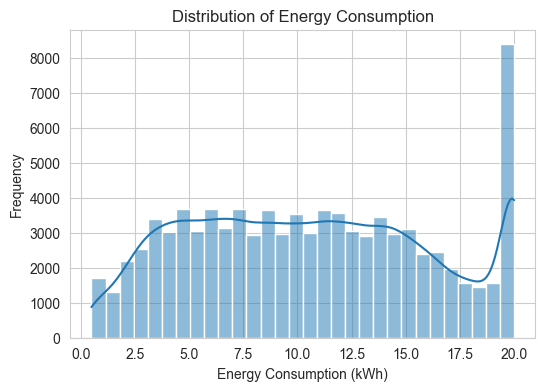

In [7]:
#distribution of energy consumption
plt.figure(figsize=(6,4))
sns.histplot(df['Energy_Consumption_kWh'],bins=30,kde=True)
plt.title("Distribution of Energy Consumption")
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Frequency")
plt.show()

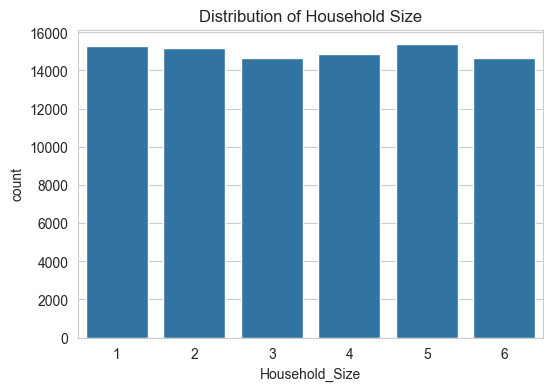

In [8]:
#Household size distribution
plt.figure(figsize=(6,4))
sns.countplot(x="Household_Size", data=df)
plt.title("Distribution of Household Size")
plt.show()

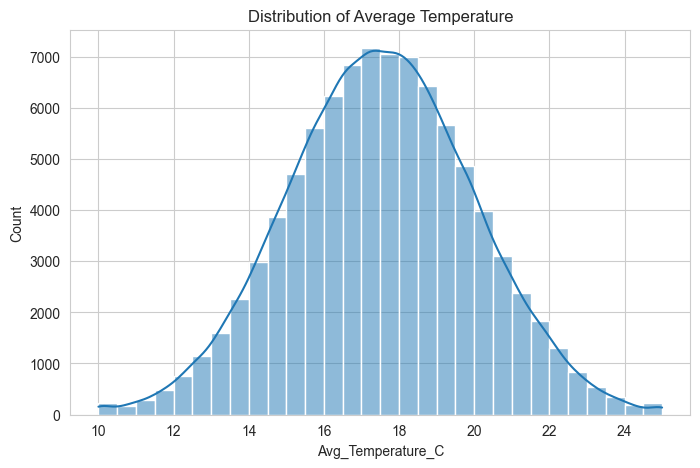

In [9]:
#Avg temp distribution
plt.figure(figsize=(8,5))
sns.histplot(df["Avg_Temperature_C"], bins=30, kde=True)
plt.title("Distribution of Average Temperature")
plt.show()

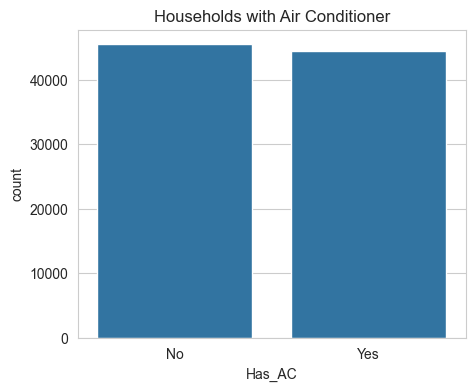

In [10]:
#AC Ownership
plt.figure(figsize=(5,4))
sns.countplot(x="Has_AC", data=df)
plt.title("Households with Air Conditioner")
plt.show()

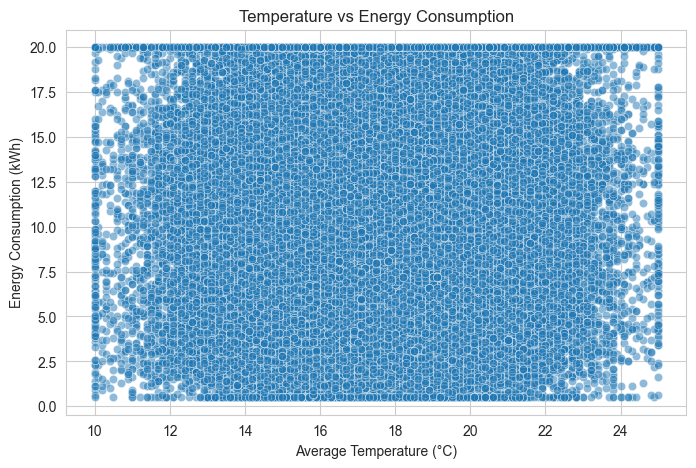

In [11]:
#temp vs energy consumption
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="Avg_Temperature_C",
    y="Energy_Consumption_kWh",
    data=df,
    alpha=0.5
)
plt.title("Temperature vs Energy Consumption")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Energy Consumption (kWh)")
plt.show()

According to this graph, there is not obvious trend, so energy consumption doesnt depend alone on temperature, so no clear relationship

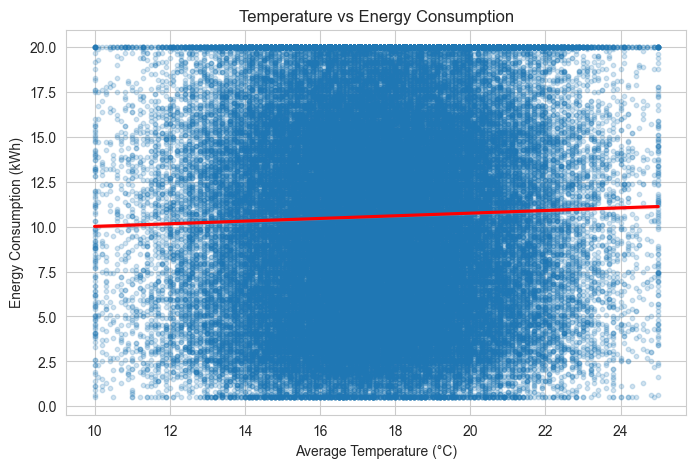

In [ ]:
plt.figure(figsize=(8,5))
sns.regplot( #Adds a regression line
    x="Avg_Temperature_C",
    y="Energy_Consumption_kWh",
    data=df,
    scatter_kws={"alpha":0.2, "s":10},
    line_kws={"color":"red"}
)
plt.title("Temperature vs Energy Consumption")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Energy Consumption (kWh)")
plt.show()

Draws a best-fit line, line is alomst horizontal meaning no linear relationship between temp and energy consumption, in real world there is a relation so most probably the dataset is synthetically generated

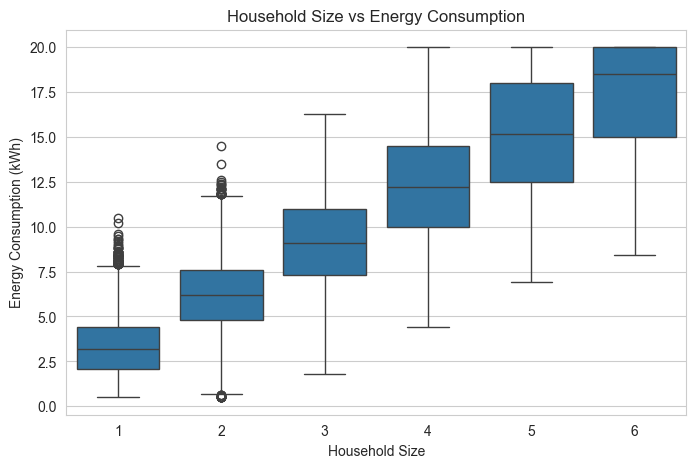

In [12]:
#Household size vs energy consumption
plt.figure(figsize=(8,5))
sns.boxplot(
    x="Household_Size",
    y="Energy_Consumption_kWh",
    data=df
)
plt.title("Household Size vs Energy Consumption")
plt.xlabel("Household Size")
plt.ylabel("Energy Consumption (kWh)")
plt.show()

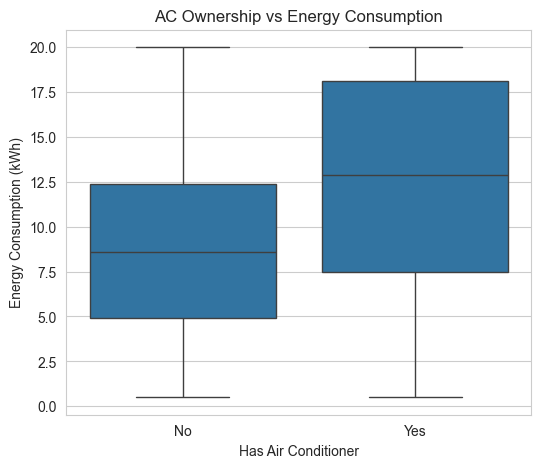

In [13]:
#Does house with AC consumes more electrivity
plt.figure(figsize=(6,5))
sns.boxplot(
    x="Has_AC",
    y="Energy_Consumption_kWh",
    data=df
)
plt.title("AC Ownership vs Energy Consumption")
plt.xlabel("Has Air Conditioner")
plt.ylabel("Energy Consumption (kWh)")
plt.show()

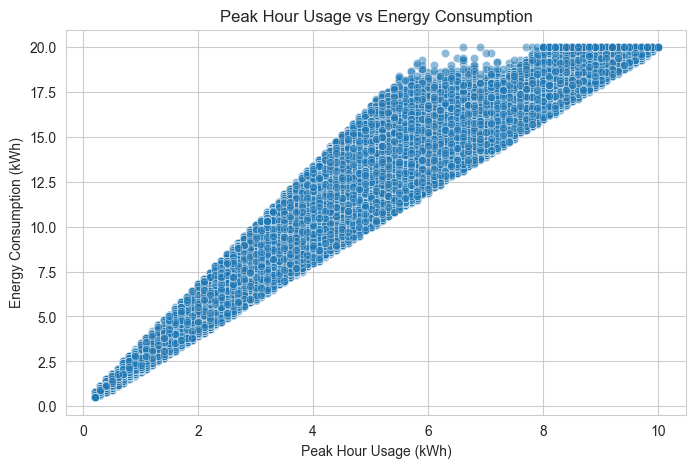

In [14]:
#Peak hour usage vs energy
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="Peak_Hours_Usage_kWh",
    y="Energy_Consumption_kWh",
    data=df,
    alpha=0.5
)
plt.title("Peak Hour Usage vs Energy Consumption")
plt.xlabel("Peak Hour Usage (kWh)")
plt.ylabel("Energy Consumption (kWh)")
plt.show()

Household consuming more electricty during peak hours will have higher energy usage overall

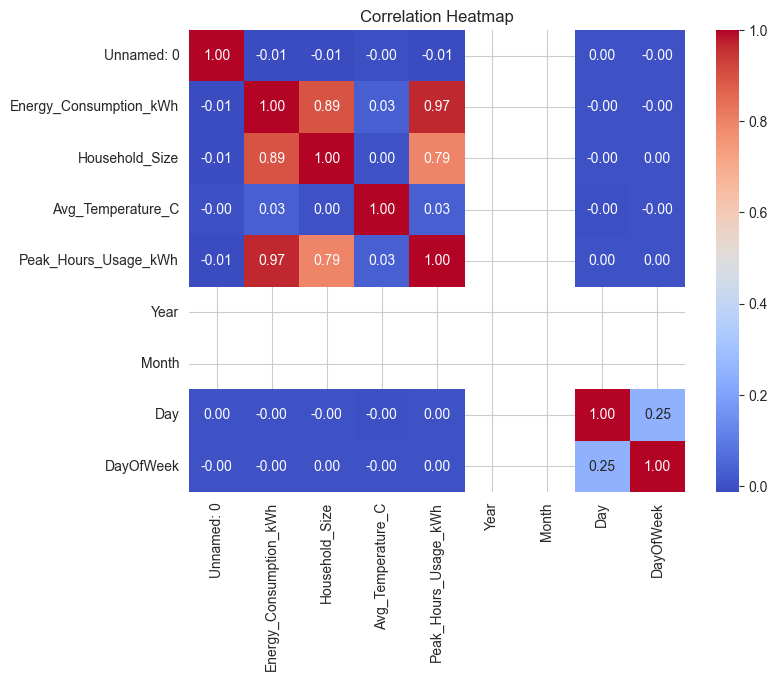

In [15]:
#Correlation
plt.figure(figsize=(8,6))
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()